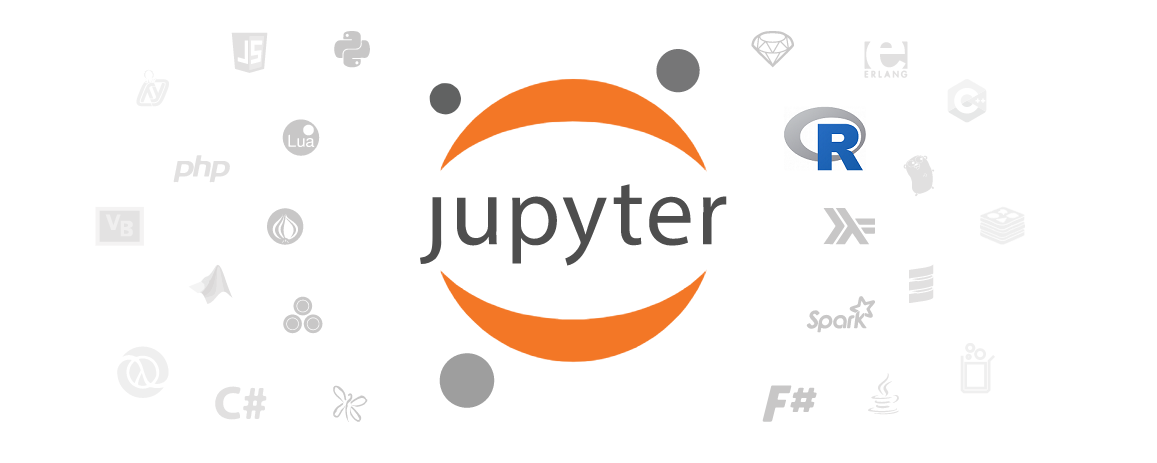

# 3. přednáška

## Načítání dat v R



<div class="alert alert-block alert-info"> 

### 1. Přehled běžných koncovek souborů a jak je v R načíst

| Koncovka | Typ souboru | Doporučený balíček | Funkce pro načtení | Poznámka |
| :--- | :--- | :--- | :--- | :--- |
| **`.csv`** | Textový | `readr` / `data.table` | `read_csv()` / `fread()` | Rychlé, všestranné a univerzální. |
| **`.txt`** | Textový (oddělovač tabulátor) | `readr` | `read_delim()` | Pro strukturovaný text. |
| **`.xlsx` / `.xls`** | MS Excel | `readxl` | `read_excel()` | Přímé načtení listů bez nutnosti instalovat Excel. |
| **`.rds`** | R Objekt (jednotlivý) | *Základní R* | `readRDS()` | Rychlé ukládání/načítání nativních datových struktur v R. |
| **`.RData`** | R Workspace (více objektů) | *Základní R* | `load()` | Načte celý uložený stav prostředí. |
| **`.parquet`** | Sloupcový formát | `arrow` | `read_parquet()` | Extrémně rychlé, efektivní komprese, ideální pro velké objemy. |
| **`.json`** | Strukturovaný text | `jsonlite` | `fromJSON()` | Běžné pro webová API. |
</div>


<div class="alert alert-block alert-info"> 

### 2. Ukázka kódu pro načítání v R

Nejčastěji se dnes místo základních funkcí (např. `read.csv()`) používají modernější a výrazně rychlejší alternativy z balíčků **`readr`**, **`data.table`** nebo **`arrow`**.

</div>

```R
# Načtení základních knihoven
library(readr)
library(data.table)
library(readxl)

# 1. Načtení CSV souboru (moderní způsob pomocí readr)
df_csv <- read_csv("data.csv")

# 2. Bleskové načtení velkého CSV (pomocí data.table)
df_fast <- fread("velka_data.csv")

# 3. Načtení konkrétního listu z Excelu
df_excel <- read_excel("report.xlsx", sheet = "Leden_2026")

# 4. Načtení uloženého R objektu (.rds)
df_rds <- readRDS("zpracovana_data.rds")

# 5. Načtení uložených proměnných (.RData)
list_load <- load("ulozene_promenne.RData")
```




<div class="alert alert-block alert-info"> 

### 3. Jak velká data R zvládne?

Limity R závisí na tom, jakým způsobem s daty pracujete:

* **In-Memory přístup (Standardní R):**
  * R ve výchozím nastavení načítá **všechna data do RAM**.
  * **Pravidlo 3× až 5×:** Pokud má vaše RAM velikost 16 GB, soubor o velikosti 2 GB po načtení a transformaci snadno zaplní 6–10 GB paměti. Bezpečný limit pro pohodlnou práci na běžném notebooku (16 GB RAM) bývají dataset s velikostí okolo **2–4 GB v surové podobě**.
* **Limit na 64-bitových systémech:**
  * Teoretický limit je dán dostupnou RAM (v serverovém prostředí i stovky GB až terabyty).
* **Out-of-Core přístup (Práce s daty bez načtení do RAM):**
  * Pomocí balíčků jako **`arrow`**, **`duckdb`** nebo **`disk.frame`** dokáže R zpracovávat **stovky gigabytů až terabyty dat** i na běžném počítači, protože si z disku čte jen ty části, které zrovna potřebuje.

</div>


<div class="alert alert-block alert-info"> 

### 4. Porovnání: R vs. Microsoft Excel

| Kritérium | Microsoft Excel | R (RStudio / Jupyter) |
| :--- | :--- | :--- |
| **Maximální řádků** | **1 048 576 řádků** (pevný limit) | **Bez pevného limitu** (omezeno pouze pamětí RAM / diskem) |
| **Rychlost načítání** | Pomalé u souborů nad 100 MB | Bleskové (např. balíček `data.table` načte 1 GB za sekundu) |
| **Reprodukovatelnost** | Nízká (ruční klikání, riziko přepsání dat) | Vysoká (veškeré kroky jsou zapsány v kódu) |
| **Automatizace & Skriptování** | Omezené (VBA / Power Query) | Plná podpora skriptování, plánování úloh a pipelines |
| **Formáty dat** | Primárně XLS/XLSX, CSV | Jakékoliv (databáze, API, Parquet, JSON, HDF5 atd.) |
| **Práce s pamětí** | Spotřebovává hodně grafických a systémových zdrojů | Efektivní práce s datovými strukturami (zejména s `arrow`/`duckdb`) |

</div>

## Matice


<div class="alert alert-block alert-success"> 

**1.** Jak uložit data do proměnných?
    
</div>

In [219]:
skoda <- c(73927, 82267)
volkswagen <- c(23754, 26598)
hyundai <- c(19688, 20992)
# spojime dohromady
vsechny <- c(skoda, volkswagen, hyundai)
# vytvorime matici
matice_prodeje <- matrix(vsechny, nrow = 3, byrow = TRUE)

<div class="alert alert-block alert-success"> 

**2.** Jak pojmenovat řádky a sloupce?
    
</div>

In [220]:
znacky <- c("Skoda", "Volkswagen", "Hyundai")
roky <- c("2015", "2016")

In [221]:
colnames(matice_prodeje) <- roky
rownames(matice_prodeje) <- znacky
matice_prodeje

,2015,2016
Skoda,73927,82267
Volkswagen,23754,26598
Hyundai,19688,20992


<div class="alert alert-block alert-success"> 

**3.** Jak zjistit celkové počty prodaných aut za oba roky pro jednotlivé značky?
    
</div>

<div class="alert alert-block alert-info"> 

Lze provést více způsoby 
 - příkazem **rowSums** 
 - přímo maticovým násobením. 
 - příkazem **apply**
  
**Pozor!** Výsledek je pokaždé jiného typu. Jazyk R rozlišuje mezi maticí a vektorem.    
</div>

In [222]:
print(rowSums(matice_prodeje))

     Skoda Volkswagen    Hyundai 
    156194      50352      40680 


In [223]:
matice_prodeje %*% matrix(1, nrow = 2, ncol = 1)

Skoda,156194
Volkswagen,50352
Hyundai,40680


In [224]:
celkem_znacky <- apply(matice_prodeje, 1, sum)

<div class="alert alert-block alert-success"> 

**4.** Jak zjistit celkové počty prodaných aut v ČR v jednotlivých letech?
    
</div>

In [225]:
celkem_roky <- colSums(matice_prodeje)

<div class="alert alert-block alert-success"> 

**5.** Jak přidat zjištěné počty do matice?
    
</div>

In [226]:
matice_prodeje_rozsirena <- cbind(matice_prodeje, celkem_znacky)

In [227]:
matice_prodeje_rozsirena <- rbind(matice_prodeje_rozsirena, c(celkem_roky, sum(matice_prodeje)))
rownames(matice_prodeje_rozsirena) <- c(rownames(matice_prodeje), "celkem za rok")
matice_prodeje_rozsirena

,2015,2016,celkem_znacky
Skoda,73927,82267,156194
Volkswagen,23754,26598,50352
Hyundai,19688,20992,40680
celkem za rok,117369,129857,247226


<div class="alert alert-block alert-success"> 

**6.** Jak určit průměrný počet prodaných aut na jednu automobilku v roce 2015?
    
</div>

In [228]:
mean(matice_prodeje[, 1])

[1] 39123

In [229]:
mean(matice_prodeje[, "2015"])

[1] 39123

<div class="alert alert-block alert-info"> 

Na sloupec pro rok 2015 se standardně odkazuje pomocí syntaxe `[ , ]`. Lze také použít příkaz **subset**, který je však vhodnější pro datové tabulky.
    
</div>

In [230]:
subset(matice_prodeje, select = "2015")

,2015
Skoda,73927
Volkswagen,23754
Hyundai,19688


<div class="alert alert-block alert-success"> 

**7.** Jak určit průměrný počet prodaných aut za rok pro automobilku Hyundai?
    
</div>

In [231]:
mean(matice_prodeje[3, ])

[1] 20340

<div class="alert alert-block alert-success"> 

**8.** Kdyby jedno jakékoliv auto stálo průměrně 16 tisíc EUR, kolik by každá automobilka utržila celkem?
    
</div>

In [232]:
matice_prodeje_rozsirena[, 3] * 16

Skoda    Volkswagen       Hyundai celkem za rok 
      2499104        805632        650880       3955616

In [233]:
matice_prodeje %*% c(16, 16)


Skoda,2499104
Volkswagen,805632
Hyundai,650880


In [234]:
rowSums(matice_prodeje) * 16

Skoda Volkswagen    Hyundai 
   2499104     805632     650880

<div class="alert alert-block alert-success"> 

**9.** Kdyby nebyla cena stejná, ale Škoda stála průměrně 17 tisíc, Volkswagen 18 tisíc a Hyundai 15 tisíc EUR, kolik by každá automobilka utržila celkem?
    
</div>

In [235]:
ceny <- c(17, 18, 15)
rowSums(matice_prodeje) * ceny

Skoda Volkswagen    Hyundai 
   2655298     906336     610200

<div class="alert alert-block alert-success"> 

**10.** Kolikrát se každé automobilce zvýšil nebo snížil prodej v roce 2016 oproti předchozímu roku?
    
</div>

In [236]:
rust <- matice_prodeje[, "2016"] / matice_prodeje[, "2015"]
rust

Skoda Volkswagen    Hyundai 
  1.112814   1.119727   1.066233

<div class="alert alert-block alert-success"> 

**11.** Která automobilka rostla v prodeji o více než 10%?
    
</div>

In [237]:
rust > 1.1

Skoda Volkswagen    Hyundai 
      TRUE       TRUE      FALSE

<div class="alert alert-block alert-success"> 

**12.** Která automobilka rostla v prodeji nejrychleji?
    
</div>

In [238]:
which.max(rust)

Volkswagen 
         2

<div class="alert alert-block alert-success"> 

**13.** Jaké byly průměrné měsíční prodeje?
    
</div>

In [239]:
matice_prodeje / 12

,2015,2016
Skoda,6160.583,6855.583
Volkswagen,1979.500,2216.500
Hyundai,1640.667,1749.333


<div class="alert alert-block alert-success"> 

**14.** Kdyby celý trh s auty tvořily jen uvedené automobilky, jakou část trhu by každá z nich pokrývala?
    
</div>

In [240]:
matice_prodeje / (matrix(1, nrow = 3) %*% colSums(matice_prodeje))

,2015,2016
Skoda,0.6298682,0.6335199
Volkswagen,0.2023873,0.2048253
Hyundai,0.1677445,0.1616547


<div class="alert alert-block alert-success"> 

**15.** Jak přidat statistiky prodeje za rok 2014, kdy Škoda prodala 58 091 vozů, Volkswagen 18 281 vozů a Hyundai 18 934 vozů?
    
</div>

In [241]:
prodej2014 <- c(58091, 18281, 18934)

In [242]:
matice2014 <- cbind(prodej2014, matice_prodeje)
colnames(matice2014)[1] <- "2014"
matice2014

,2014,2015,2016
Skoda,58091,73927,82267
Volkswagen,18281,23754,26598
Hyundai,18934,19688,20992


<div class="alert alert-block alert-success"> 

**16.** Vláda zavedla daň z každého prodaného auta, která byla 1 EUR v roce 2014 a každý rok se o 1 EUR zvyšovala. Kolik EUR celkem zaplatila každá automobilka na této dani?
    
</div>

In [243]:
vydaje <- matice2014 %*% matrix(c(1, 2, 3), nrow = 3)

<div class="alert alert-block alert-success"> 

**17.** Jak by tato daň měla být v jednotlivých letech nastavená, aby Škoda zaplatila 454, Volkswagen 146 a Hyundai 122 tisíc EUR?
    
</div>

In [244]:
dan <- c(454, 146, 122)
solve(matice2014, dan) * 1000

2014      2015      2016 
1.3486377 0.7389787 3.9022428

<div class="alert alert-block alert-success"> 

**18.** Pro kterou automobilku by bylo nové nastavení daní nejvýhodnější?
    
</div>

In [245]:
vydaje
dan*1000
(vydaje - dan*1000) / vydaje

Skoda,452746
Volkswagen,145583
Hyundai,121286


[1] 454000 146000 122000

Skoda,-0.002769765
Volkswagen,-0.002864345
Hyundai,-0.005886912


In [246]:
dan*1000 / vydaje

Skoda,1.002770
Volkswagen,1.002864
Hyundai,1.005887


## Pole

<div class="alert alert-block alert-success"> 

**19.** Jak uložit data do proměnné?
    
</div>

In [247]:
B_2015 <- c(41075, 9914, 12526)
B_2016 <- c(42570, 11904, 13751)
N_2015 <- c(30575, 13154, 7114)
N_2016 <- c(37204, 14106, 7162)
# spojime dohromady
vsechny <- c(B_2015, B_2016, N_2015, N_2016)
# vytvorime pole
pole_prodeje <- array(vsechny, dim = c(3,2,2))

In [248]:
vsechny

[1] 41075  9914 12526 42570 11904 13751 30575 13154  7114 37204 14106  7162

In [249]:
print(pole_prodeje)

, , 1

      [,1]  [,2]
[1,] 41075 42570
[2,]  9914 11904
[3,] 12526 13751

, , 2

      [,1]  [,2]
[1,] 30575 37204
[2,] 13154 14106
[3,]  7114  7162



<div class="alert alert-block alert-danger"> 

Pole se definuje příkazem **array**.
    
</div>

<div class="alert alert-block alert-success"> 

**20.** Jak pojmenovat dimenze? 
    
</div>

In [250]:
paliva <- c("benzin", "nafta")

In [251]:
dimnames(pole_prodeje)[[1]] <- znacky
dimnames(pole_prodeje)[[2]] <- roky
dimnames(pole_prodeje)[[3]] <- paliva
print(pole_prodeje)

, , benzin

            2015  2016
Skoda      41075 42570
Volkswagen  9914 11904
Hyundai    12526 13751

, , nafta

            2015  2016
Skoda      30575 37204
Volkswagen 13154 14106
Hyundai     7114  7162



In [252]:
pole_prodeje <- array(vsechny, dim = c(3,2,2), dimnames = list(znacky, roky, paliva))

<div class="alert alert-block alert-success"> 

**21.** Jak zjistit celkové počty prodaných aut s benzinovým motorem za oba roky pro jednotlivé značky?
    
</div>

In [253]:
rowSums(pole_prodeje[ , , "benzin"])

Skoda Volkswagen    Hyundai 
     83645      21818      26277

<div class="alert alert-block alert-success"> 

**22.** Jak zjistit celkové počty aut s naftovym motorem prodaných v ČR v jednotlivých letech?
    
</div>

In [254]:
colSums(pole_prodeje[ , , "nafta"])

2015  2016 
50843 58472

<div class="alert alert-block alert-success"> 

**23.** Jak zjistit součty naftových a benzinových aut dohromady? 
    
</div>

In [255]:
pole_prodeje[ , , 1] + pole_prodeje[ , , 2]

,2015,2016
Skoda,71650,79774
Volkswagen,23068,26010
Hyundai,19640,20913


In [256]:
matice_prodeje

,2015,2016
Skoda,73927,82267
Volkswagen,23754,26598
Hyundai,19688,20992


In [257]:
oba <- apply(pole_prodeje, c(1, 2), sum)

<div class="alert alert-block alert-warning"> 

Proč součet nesouhlasí s maticí z předchozího příkladu?
    
</div>

<div class="alert alert-block alert-success"> 

**24.** Jak určit průměrný počet benzinovych a naftovych aut na jednu automobilku v roce 2015?
    
</div>

In [258]:
colMeans(pole_prodeje[ , "2015", ])

benzin    nafta 
21171.67 16947.67

<div class="alert alert-block alert-success"> 

**25.** Jak určit průměrný počet benzinovych a naftovych aut za rok pro automobilku Hyundai?
    
</div>

In [259]:
colMeans(pole_prodeje["Hyundai", , ])

benzin   nafta 
13138.5  7138.0

<div class="alert alert-block alert-success"> 

**26.** Kolikrát se každé automobilce zvýšil nebo snížil prodej v roce 2016 oproti předchozímu roku?
    
</div>

In [260]:
rust <- pole_prodeje[, "2016", ] / pole_prodeje[ , "2015", ]
rust

,benzin,nafta
Skoda,1.036397,1.216811
Volkswagen,1.200726,1.072373
Hyundai,1.097797,1.006747


<div class="alert alert-block alert-success"> 

**27.** Která automobilka a pro jaký typ motoru rostla o více než 20%?
    
</div>

In [261]:
rust > 1.2

,benzin,nafta
Skoda,FALSE,TRUE
Volkswagen,TRUE,FALSE
Hyundai,FALSE,FALSE


<div class="alert alert-block alert-success"> 

**28.** Která automobilka rostla v prodeji nejrychleji?
    
</div>

In [262]:
which.max(rust)
# jde po sloupcich, takze to je Skoda v nafte

[1] 4

<div class="alert alert-block alert-success"> 

**29.** Jak přidat další tabulku, jejíž hodnoty budou počty prodaných aut s jiným typem motoru?
    
</div>

In [283]:
pole_prodeje <- array(c(pole_prodeje, oba), dim = c(3, 2, 3))
print(pole_prodeje)

, , 1

      [,1]  [,2]
[1,] 41075 42570
[2,]  9914 11904
[3,] 12526 13751

, , 2

      [,1]  [,2]
[1,] 30575 37204
[2,] 13154 14106
[3,]  7114  7162

, , 3

      [,1]  [,2]
[1,] 71650 79774
[2,] 23068 26010
[3,] 19640 20913



<div class="alert alert-block alert-success"> 

**30.** Jak zjistit, kolik procent produkce zaujímá daný typ motoru pro každou automobilku a každý rok?
    
</div>

In [298]:
total <- pole_prodeje[, , 1] + pole_prodeje[ , , 2] + pole_prodeje[ , , 3]
total
pole_prodeje[ , , 3] / total

143300,159548
46136,52020
39280,41826


0.5,0.5
0.5,0.5
0.5,0.5


In [299]:
apply(pole_prodeje, c(1, 2), sum)

143300,159548
46136,52020
39280,41826
